In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold

from scikeras.wrappers import KerasRegressor


from sklearn.metrics import mean_absolute_error

In [70]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [71]:
# Fix random state
random_state = 42

In [72]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [73]:
apogee = apogee[apogee.parallax >2]
print (len(apogee))
galah = galah[galah.parallax > 3]
print (len(galah))


23511
19678


# Here we focus on getting Fe from no abundance

In [74]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', # 'parallax',  #'pmra', 'pmdec', #'ra', 'dec',
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

### Identifying and exluding null values

In [75]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [76]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [77]:
#gr8.isnull().sum() # No null values

In [78]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [79]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train, X_gr8], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train, y_gr8], ignore_index=True)


In [80]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)



model_names = {
    'xgbr': xgbr,
    'lgbr': lgbr,
}


In [81]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np
import time
from copy import deepcopy

def model_test_CV_models(X, y, models, k=5, random_state=42, target_transformer=None):
    """
    Perform k-fold CV with optional target transformation. Returns MAE stats and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.
        target_transformer (sklearn transformer or None): e.g., StandardScaler(), QuantileTransformer()

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Copy the transformer and fit only on training data
            if target_transformer is not None:
                transformer = deepcopy(target_transformer)
                y_train_trans = transformer.fit_transform(y_train.values.reshape(-1, 1)).flatten()
            else:
                y_train_trans = y_train

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train_trans)
            y_pred = model.predict(X_test)

            # Inverse-transform predictions
            if target_transformer is not None:
                y_pred = transformer.inverse_transform(np.array(y_pred).reshape(-1, 1)).flatten()

            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [82]:
from sklearn.preprocessing import StandardScaler, QuantileTransformer


baseline_results = model_test_CV_models(X_combined_train, y_combined_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 0.84s → MAE: 0.143 ± 0.001

Scoring model: lgbr
lgbr done in 1.85s → MAE: 0.139 ± 0.001

xgbr     | MAE: 0.143 ± 0.001
lgbr     | MAE: 0.139 ± 0.001


In [83]:
from sklearn.preprocessing import StandardScaler

standard_results = model_test_CV_models(X_combined_train, y_combined_train, model_names, k=5, target_transformer=StandardScaler())

for name, score in standard_results.items():
    print(f"{name:8s} | MAE (scaled): {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 0.88s → MAE: 0.143 ± 0.001

Scoring model: lgbr
lgbr done in 2.04s → MAE: 0.139 ± 0.001

xgbr     | MAE (scaled): 0.143 ± 0.001
lgbr     | MAE (scaled): 0.139 ± 0.001


In [84]:
from sklearn.preprocessing import QuantileTransformer

quantile_results = model_test_CV_models(X_combined_train, y_combined_train, model_names, k=5, target_transformer=QuantileTransformer(output_distribution='normal'))

for name, score in quantile_results.items():
    print(f"{name:8s} | MAE (quantile): {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 0.86s → MAE: 0.143 ± 0.001

Scoring model: lgbr
lgbr done in 2.01s → MAE: 0.139 ± 0.001

xgbr     | MAE (quantile): 0.143 ± 0.001
lgbr     | MAE (quantile): 0.139 ± 0.001


In [ ]:
from copy import deepcopy
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

def evaluate_on_test_data(
    X_train, y_train,
    test_df, target,
    models,
    test_name='Test',
    target_transformer=None
):
    """
    Trains models on the full training set and evaluates on an external test set.
    Optionally applies a transformation to the target during training.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').
        target_transformer: A sklearn transformer (e.g., StandardScaler, QuantileTransformer) or None.

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")

        # Copy the transformer and fit on y_train only
        if target_transformer is not None:
            transformer = deepcopy(target_transformer)
            y_train_trans = transformer.fit_transform(y_train.values.reshape(-1, 1)).flatten()
        else:
            y_train_trans = y_train

        model.fit(X_train, y_train_trans)
        y_pred = model.predict(X_test)

        # Inverse transform predictions if needed
        if target_transformer is not None:
            y_pred = transformer.inverse_transform(np.array(y_pred).reshape(-1, 1)).flatten()

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results

In [86]:
# StandardScaler
evaluate_on_test_data(X_combined_train, y_combined_train, harps, 'fe_h', model_names, test_name='HARPS', target_transformer=StandardScaler())

# QuantileTransformer
evaluate_on_test_data(X_combined_train, y_combined_train, harps, 'fe_h', model_names, test_name='HARPS', target_transformer=QuantileTransformer(output_distribution='normal'))

# eo-johnson
evaluate_on_test_data(X_combined_train, y_combined_train, harps, 'fe_h', model_names, test_name='HARPS', target_transformer=PowerTransformer(method='yeo-johnson'))

# No transformation
evaluate_on_test_data(X_combined_train, y_combined_train, harps, 'fe_h', model_names, test_name='HARPS', target_transformer=None)


Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.174 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.172 (mean baseline: 0.204)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.177 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.176 (mean baseline: 0.204)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.179 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.177 (mean baseline: 0.204)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.174 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.172 (mean baseline: 0.204)



{'xgbr': {'mae_model': 0.17434096066164784,
  'mae_baseline': 0.20415738594606817},
 'lgbr': {'mae_model': 0.17247654964112025,
  'mae_baseline': 0.20415738594606817}}

In [87]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


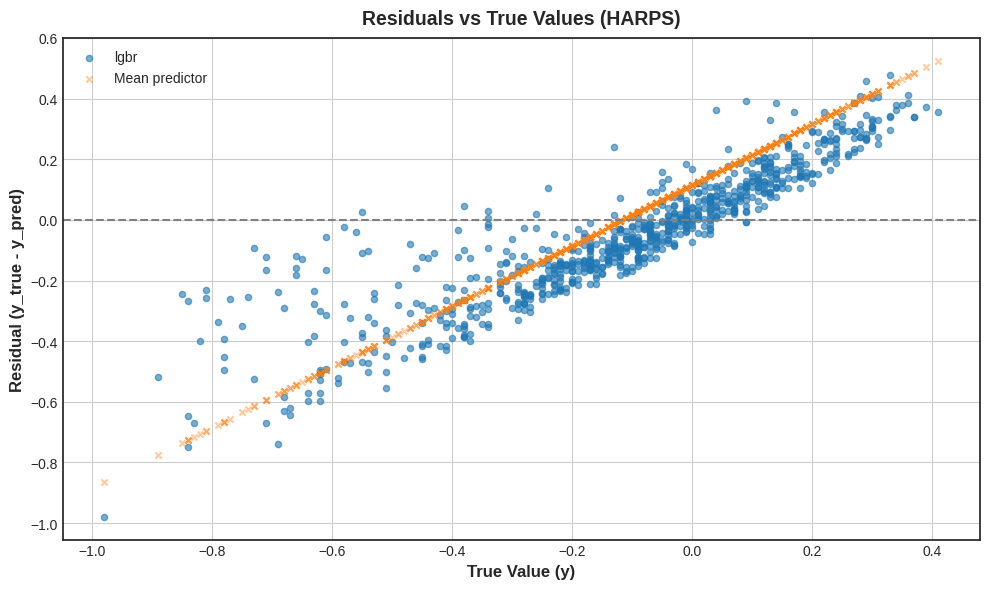

In [88]:
from sklearn.preprocessing import StandardScaler  # or any transformer
import numpy as np
from copy import deepcopy

# Initialize and fit target transformer
target_transformer = StandardScaler()
y_combined_train_trans = target_transformer.fit_transform(y_combined_train.values.reshape(-1, 1)).flatten()

# Train model with transformed y
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train_trans)

# Predict on test set
y_pred_harps_trans = model.predict(X_harps)

# Inverse transform predictions
y_pred_harps = target_transformer.inverse_transform(
    np.array(y_pred_harps_trans).reshape(-1, 1)
).flatten()

# Plot residuals
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

